# MedAESQA — Human Judgment Scores EDA



In [1]:
DATA_PATH = "medaesqa_v1.json"
import os
print(os.listdir())

['.config', 'sample_data']


In [2]:
from google.colab import files
uploaded = files.upload()

Saving medaesqa_v1.json to medaesqa_v1.json


In [3]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 100)

with open(DATA_PATH, "r", encoding="utf-8") as f:
    data = json.load(f)

print(f"{len(data)} questions loaded")

40 questions loaded


## 1. Flatten into three tables


In [5]:
answer_rows, sentence_rows, citation_rows = [], [], []

for item in data:
    qid = item["question_id"]
    for method_id, m in item["machine_generated_answers"].items():
        answer_rows.append({
            "question_id": qid,
            "method_id": method_id,
            "is_answer_accurate": m.get("is_answer_accurate"),
            "n_sentences": len(m.get("answer_sentences", [])),
        })
        for s in m.get("answer_sentences", []):
            sid = s.get("answer_sentence_id")
            sentence_rows.append({
                "question_id": qid,
                "method_id": method_id,
                "sentence_id": sid,
                "relevance": s.get("answer_sentence_relevance"),
                "n_citations": len(s.get("citation_assessment") or []),
            })
            for c in s.get("citation_assessment") or []:
                citation_rows.append({
                    "question_id": qid,
                    "method_id": method_id,
                    "sentence_id": sid,
                    "cited_pmid": c.get("cited_pmid"),
                    "evidence_relation": c.get("evidence_relation"),
                    "has_excerpt": c.get("evidence_support") is not None,
                })

answers_df = pd.DataFrame(answer_rows)
sentences_df = pd.DataFrame(sentence_rows)
citations_df = pd.DataFrame(citation_rows)

print("answers:", answers_df.shape, "| sentences:", sentences_df.shape, "| citations:", citations_df.shape)
answers_df.head()

answers: (1200, 4) | sentences: (5162, 5) | citations: (9611, 6)


,question_id,method_id,is_answer_accurate,n_sentences
0,116,M1,yes,6
1,116,M2,yes,7
2,116,M3,yes,6
3,116,M4,yes,6
4,116,M5,no,4


## 2. Answer-level accuracy
How often is a machine-generated answer judged fully accurate, and does that vary by method?

Overall accuracy rate across all 1,200 (question x method) answers:
is_answer_accurate
yes    0.918333
no     0.081667
Name: proportion, dtype: float64


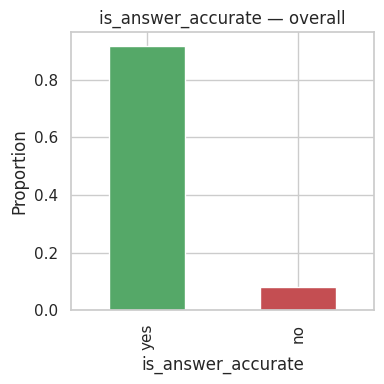

In [6]:
overall_acc = answers_df["is_answer_accurate"].value_counts(normalize=True)
print("Overall accuracy rate across all 1,200 (question x method) answers:")
print(overall_acc)

fig, ax = plt.subplots(figsize=(4,4))
overall_acc.plot(kind="bar", ax=ax, color=["#55A868","#C44E52"])
ax.set_ylabel("Proportion")
ax.set_title("is_answer_accurate — overall")
plt.tight_layout()
plt.show()

In [7]:
# Accuracy rate per method (M1..M30) - sorted by accuracy
acc_by_method = (
    (answers_df["is_answer_accurate"] == "yes")
    .groupby(answers_df["method_id"])
    .mean()
    .sort_values(ascending=False)
)

acc_by_method.to_frame("accuracy_rate")

,accuracy_rate
method_id,
M10,1.000
M16,1.000
M19,1.000
M2,1.000
M17,1.000
M25,1.000
M26,1.000
M27,1.000
M6,1.000


## 3. Sentence-level relevance
Each sentence in each machine answer is labeled by relevance to the question.

relevance
required         3958
unnecessary       698
None              244
borderline        243
inappropriate      19
Name: count, dtype: int64


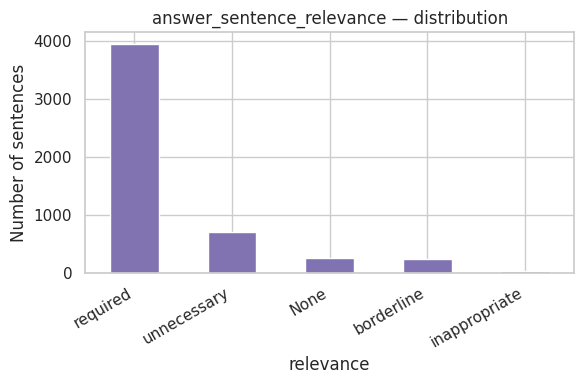

In [8]:
rel_counts = sentences_df["relevance"].value_counts(dropna=False)
print(rel_counts)

fig, ax = plt.subplots(figsize=(6,4))
rel_counts.plot(kind="bar", ax=ax, color="#8172B2")
ax.set_ylabel("Number of sentences")
ax.set_title("answer_sentence_relevance — distribution")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 4. Citation-level evidence relation
For every cited PMID in every sentence, humans judged whether the cited evidence actually supports the claim.

evidence_relation
supporting          6490
not relevant        1551
neutral              972
invalid citation     409
contradicting        189
Name: count, dtype: int64

Non-null evidence excerpts (has_excerpt=True): 7651  (paper reports 7,651 — MATCH)


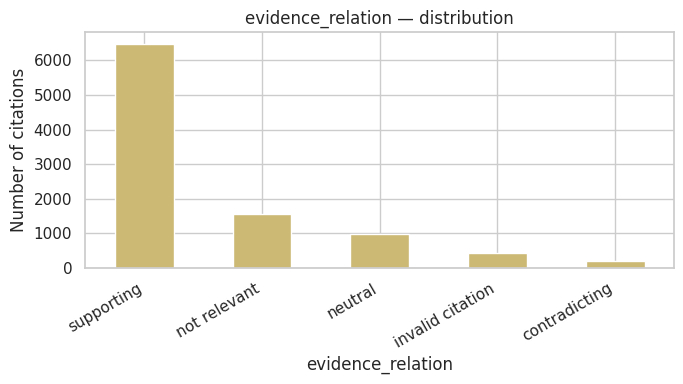

In [9]:
rel_counts_cit = citations_df["evidence_relation"].value_counts(dropna=False)
print(rel_counts_cit)
print()
print(f"Non-null evidence excerpts (has_excerpt=True): {citations_df['has_excerpt'].sum()}  "
      f"(paper reports 7,651 — {'MATCH' if citations_df['has_excerpt'].sum()==7651 else 'mismatch, check parsing'})")

fig, ax = plt.subplots(figsize=(7,4))
rel_counts_cit.plot(kind="bar", ax=ax, color="#CCB974")
ax.set_ylabel("Number of citations")
ax.set_title("evidence_relation — distribution")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 5. Faithfulness proxy per method
Fraction of a method's citations that are judged 'supporting' vs. contradicting/not-relevant/invalid — a rough per-method faithfulness signal, independent of overall answer accuracy.

In [10]:
faith_by_method = (
    (citations_df["evidence_relation"] == "supporting")
    .groupby(citations_df["method_id"])
    .mean()
    .sort_values(ascending=False)
)

faith_by_method.to_frame("pct_supporting_citations")

,pct_supporting_citations
method_id,
M7,0.852459
M26,0.787472
M11,0.778032
M6,0.760000
M14,0.746377
M19,0.743820
M1,0.736318
M4,0.734742
M20,0.731207


## 6. Answer Accuracy vs Citation Faithfulness


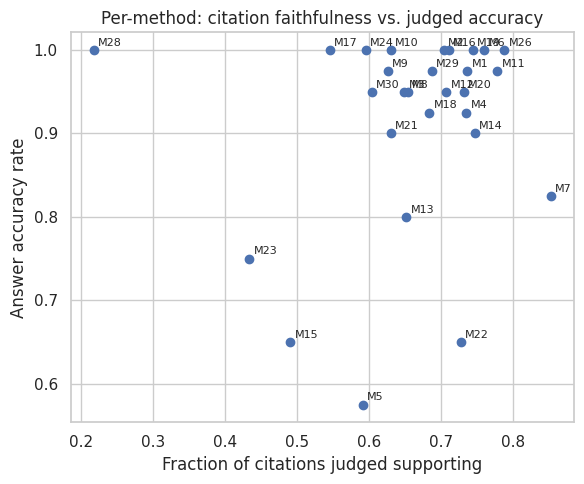

Correlation (Pearson): 0.156


,accuracy_rate,pct_supporting_citations
method_id,,
M10,1.000,0.630435
M16,1.000,0.711009
M19,1.000,0.743820
M2,1.000,0.703704
M17,1.000,0.545120
M25,1.000,NaN
M26,1.000,0.787472
M27,1.000,NaN
M6,1.000,0.760000


In [11]:
compare = pd.concat([acc_by_method.rename("accuracy_rate"),
                      faith_by_method.rename("pct_supporting_citations")], axis=1)

fig, ax = plt.subplots(figsize=(6,5))
ax.scatter(compare["pct_supporting_citations"], compare["accuracy_rate"])
for method_id, row in compare.iterrows():
    ax.annotate(method_id, (row["pct_supporting_citations"], row["accuracy_rate"]), fontsize=8,
                xytext=(3,3), textcoords="offset points")
ax.set_xlabel("Fraction of citations judged supporting")
ax.set_ylabel("Answer accuracy rate")
ax.set_title("Per-method: citation faithfulness vs. judged accuracy")
plt.tight_layout()
plt.show()

print("Correlation (Pearson):", compare["pct_supporting_citations"].corr(compare["accuracy_rate"]).round(3))
compare.sort_values("accuracy_rate", ascending=False)